<a href="https://colab.research.google.com/github/nguyenbahieuthien0811-art/YOLO-Vision-Real-Time-Person-Detection/blob/main/cv2demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
    # Step 1: Install libraries
!pip install opencv-python ultralytics # opencv-python: thư viện xử lý ảnh,video |ultralytics: thư viện chứa model Yolo
import cv2 # cv2 dùng xử lý ảnh,video
from ultralytics import YOLO #import yolo từ thư viện ultralytics
import matplotlib.pyplot as plt # dùng để vẽ hình
from google.colab import files
import numpy as np #numpy: thư viện dùng để tính toán

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving YTDown.com_YouTube_Media_AlnHNi0hdO0_Ankara-Messi-Kara-Messi_001_720p.mp4 to YTDown.com_YouTube_Media_AlnHNi0hdO0_Ankara-Messi-Kara-Messi_001_720p.mp4

0: 384x640 4 persons, 376.0ms
Speed: 26.0ms preprocess, 376.0ms inference, 37.7ms postprocess per image at shape (1, 3, 384, 640)


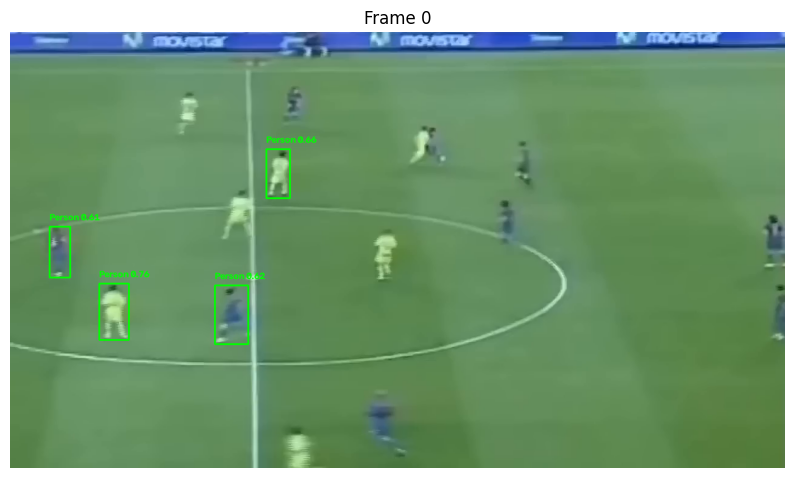


0: 384x640 8 persons, 122.4ms
Speed: 5.5ms preprocess, 122.4ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)


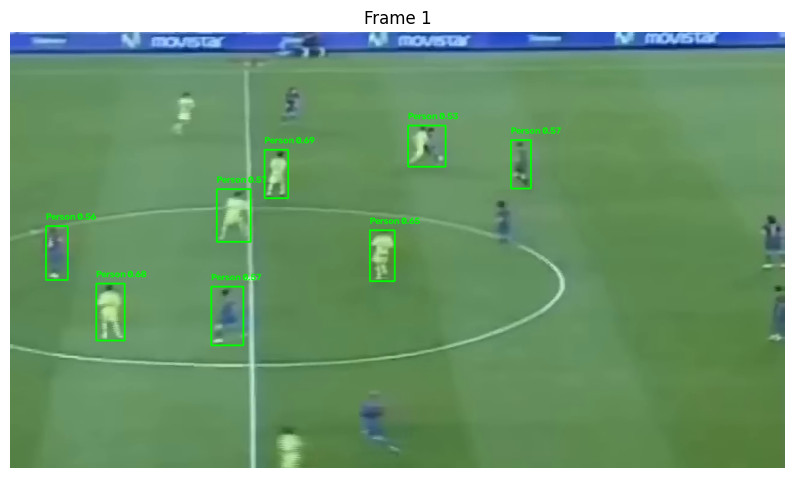


0: 384x640 2 persons, 113.9ms
Speed: 6.0ms preprocess, 113.9ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)


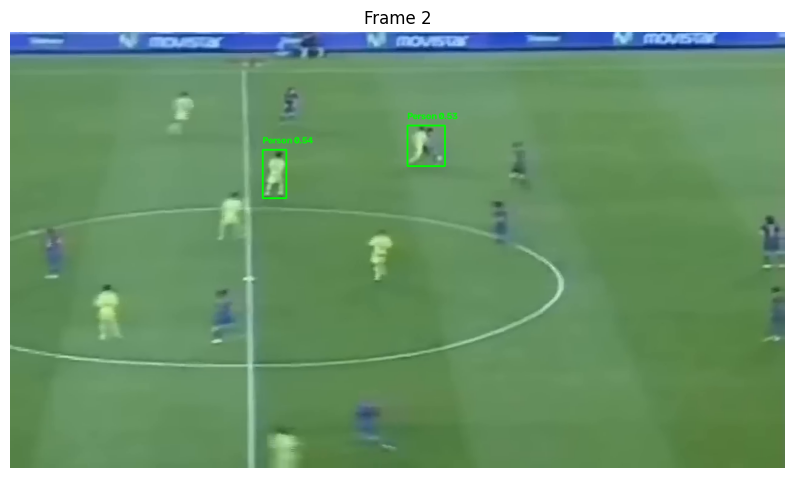


0: 384x640 1 person, 114.6ms
Speed: 5.1ms preprocess, 114.6ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)


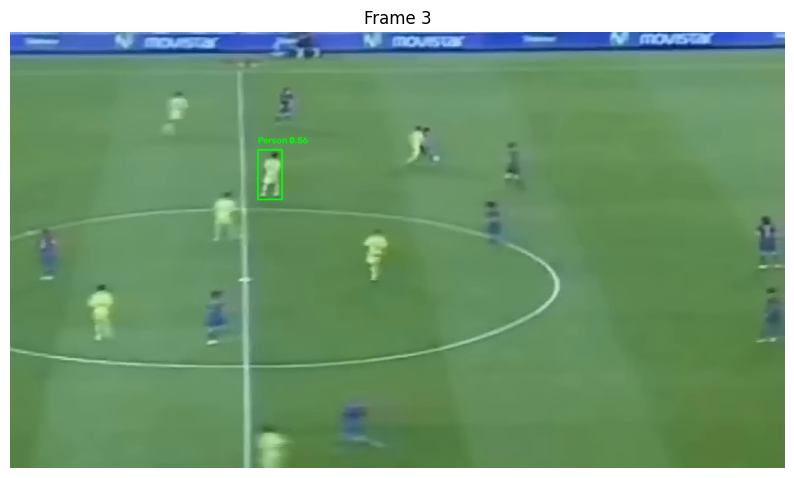


0: 384x640 (no detections), 138.5ms
Speed: 6.4ms preprocess, 138.5ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)


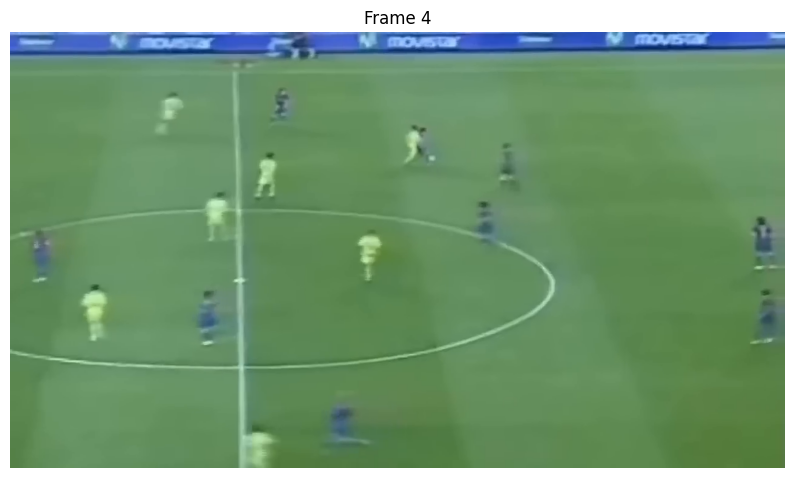


0: 384x640 (no detections), 141.6ms
Speed: 7.3ms preprocess, 141.6ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 130.9ms
Speed: 9.3ms preprocess, 130.9ms inference, 0.9ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 126.3ms
Speed: 5.9ms preprocess, 126.3ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 128.3ms
Speed: 7.5ms preprocess, 128.3ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 132.5ms
Speed: 5.5ms preprocess, 132.5ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 132.7ms
Speed: 8.2ms preprocess, 132.7ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 161.0ms
Speed: 7.2ms preprocess, 161.0ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 137.3ms
Speed: 7.3ms preprocess, 137.3ms

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Processed 634 frames


In [ ]:
#Step 2: Upload video files
upload = files.upload()
video_patch = list(upload.keys())[0] # get the upload video file name

#Step 3: Load the pretraied YOLO model
model = YOLO('/content/yolo11n.pt') #load model yolo đã huấn luyễn
#Step 4: Set model to only detect 'person' (class ID = 0 in COCO data set)
cap = cv2.VideoCapture(video_patch) #mở file video đọc từng frame
#check if video opended
if not cap.isOpened():
    print("Error opening video file")
    exit()
from torch import hinge_embedding_loss
#Step 5: get video properties
fps = int(cap.get(cv2.CAP_PROP_FPS)) #số khung hình trên giây
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) #chiều rộng vid
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) #chiều cao vid

#Step 6: Define the output video writer
output_path = 'output_video.mp4' #file output
fourcc = cv2.VideoWriter_fourcc(*'mp4v') #kết quả trả về là vid
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height)) #ghi từng frame vid
# Step 7: Process video frame by frame
frame_count = 0 #số frame
max_display_frames = 5 #số frame tối đa 1 lúc
display_frame = 0 #số frame hiển thị 1 lúc


while cap.isOpened():
    ret, frame = cap.read() #ret true khi video chạy thành công
    if not ret: #false ==> hết vid
        break  # Exit if no frame left
    # Run inference
    results = model.predict(source=frame, imgsz=640, conf=0.5) #chạy model yolo

    # Draw bounding boxes and label on the frame
    for result in results[0].boxes:
        x1, y1, x2, y2 = map(int, result.xyxy[0]) #lấy tọa đọ góc
        confidence = result.conf[0] #xác xuất dự đoán đúng của Yolo
        class_id = int(result.cls[0])

        # Draw bounding box and label if the detected class is person
        if class_id == 0:  # 0 usually represents 'person' in COCO dataset
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2) #khung hình chữ nhật
            label = f'Person {confidence:.2f}'  #tạo text person
            cv2.putText(frame, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2) #viết trữ lên(frame,nội dung,vị trí, font,kích thước, màu, độ dày nét chữ)

    # Write the frame to the output video
    out.write(frame) #ghi frame đã vẽ để tạo vid
    # Display a few frames in Colab using matplotlib

    if display_frame < max_display_frames: #kiểm tra đã hiển thị bào nhiêu frame
        plt.figure(figsize=(10, 6))  #tạo một figure khung vẽ
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))  # Convert BGR to RGB for correct colors
        plt.axis('off') #tắt hiển thịc trục tọa độ
        plt.title(f"Frame {frame_count}") #tiêu đề frame
        plt.show() #hiển thị figure
        display_frame += 1 #hiển thị thêm một frame

    frame_count += 1 #tăng số đã xử lý
# Release resources
cap.release() #đóng file input
out.release() #đóng file output

    # Step 8: Save the output video
files.download(output_path) #tải file output về máy
print(f"Processed {frame_count} frames") #in số frame đã xử lý

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Processed 0 frames



0: 384x640 9 persons, 292.8ms
Speed: 18.5ms preprocess, 292.8ms inference, 35.0ms postprocess per image at shape (1, 3, 384, 640)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Processed 0 frames
